## 层次分析法（AHP）

**思路三步走：**

1. **构造判断矩阵**：同一层次内各因素两两比较，用 1~9 标度打分（$a_{ij}$ 表示 $i$ 相对 $j$ 的重要程度，$a_{ij}\cdot a_{ji}=1$，对角线为 1）
2. **求权重**：求最大特征值 $\lambda_{max}$ 对应的特征向量，并归一化
3. **一致性检验**：$CI=\frac{\lambda_{max}-n}{n-1}$，$CR=\frac{CI}{RI}$，当 $CR<0.1$ 时认为判断矩阵可接受

**1~9 标度含义**

| 标度 | 含义 |
| --- | --- |
| 1 | 两者同等重要 |
| 3 | 前者稍重要 |
| 5 | 前者明显重要 |
| 7 | 前者强烈重要 |
| 9 | 前者极端重要 |
| 2,4,6,8 | 上述判断的中间值 |
| 倒数 | $a_{ji}=1/a_{ij}$ |

In [ ]:
# 层次分析法 AHP（Python 3.11）
import sys
import numpy as np
import matplotlib.pyplot as plt

# 中文字体，避免图表中文乱码
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 随机一致性指标 RI（n = 1~10）
RI = [0.0, 0.0, 0.58, 0.90, 1.12, 1.24, 1.32, 1.41, 1.45, 1.49]

print("Python 版本：", sys.version.split()[0])

Python 版本： 3.11.9


In [ ]:
# AHP 核心函数：特征值法求权重 + 一致性检验
def ahp(matrix, names=None, verbose=True):
    A = np.asarray(matrix, dtype=float)
    n = A.shape[0]

    # 合法性检查（方阵、对角线为 1、互反性）
    if A.ndim != 2 or A.shape != (n, n):
        raise ValueError("判断矩阵必须是方阵")
    if not np.allclose(np.diag(A), 1):
        raise ValueError("对角线元素必须为 1")
    if not np.allclose(A * A.T, 1):
        raise ValueError("必须满足互反性：a_ij * a_ji = 1")

    # 1. 最大特征值及其对应的特征向量
    eigvals, eigvecs = np.linalg.eig(A)
    k = int(np.argmax(eigvals.real))
    lambda_max = eigvals[k].real
    w = np.abs(eigvecs[:, k].real)
    w = w / w.sum()                      
    # 归一化得到权重
    # 2. 一致性检验
    CI = (lambda_max - n) / (n - 1) if n > 1 else 0.0
    CR = CI / RI[n - 1] if RI[n - 1] > 0 else 0.0

    # 3. 输出结果
    if verbose:
        names = names or [f"准则{i + 1}" for i in range(n)]
        for name, wi in zip(names, w):
            print(f"{name:<6s} 权重 = {wi:.4f}  {'█' * int(round(wi * 40))}")
        print(f"λmax = {lambda_max:.4f}, CI = {CI:.4f}, RI = {RI[n - 1]:.2f}, CR = {CR:.4f}")
        print("一致性检验：" + ("通过 ✅" if CR < 0.1 else "未通过 ❌，请调整判断矩阵"))

    return w, CR

In [ ]:
# 示例 1：4 个准则的权重计算
criteria = ["景色", "费用", "居住", "饮食"]
A = np.array([
    [1,     1 / 2, 4,   3    ],
    [2,     1,     7,   5    ],
    [1 / 4, 1 / 7, 1,   1 / 2],
    [1 / 3, 1 / 5, 2,   1    ],
])

w, CR = ahp(A, criteria)
print("\n准则权重（保留 4 位）：", np.round(w, 4))

景色     权重 = 0.2884  ████████████
费用     权重 = 0.5323  █████████████████████
居住     权重 = 0.0675  ███
饮食     权重 = 0.1118  ████
λmax = 4.0215, CI = 0.0072, RI = 0.90, CR = 0.0080
一致性检验：通过 ✅

准则权重（保留 4 位）： [0.2884 0.5323 0.0675 0.1118]


In [ ]:
# 示例 2：方案层打分 -> 综合得分排名
places = ["成都", "上海", "威海"]
B = {  # 每个准则下 3 个候选地的判断矩阵
    "景色": np.array([[1, 2, 5], [1 / 2, 1, 3], [1 / 5, 1 / 3, 1]]),
    "费用": np.array([[1, 1 / 3, 1 / 2], [3, 1, 2], [2, 1 / 2, 1]]),
    "居住": np.array([[1, 3, 2], [1 / 3, 1, 1 / 2], [1 / 2, 2, 1]]),
    "饮食": np.array([[1, 2, 1], [1 / 2, 1, 1 / 2], [1, 2, 1]]),
}

score = np.zeros(len(places))
for j, c in enumerate(criteria):
    wc, cr_c = ahp(B[c], places, verbose=False)
    print(f"[{c}] 权重 = {np.round(wc, 3)}  CR = {cr_c:.3f}")
    score += w[j] * wc          # 加权求和

print("\n综合得分排名：")
for name, s in sorted(zip(places, score), key=lambda t: -t[1]):
    print(f"  {name}: {s:.4f}")

[景色] 权重 = [0.582 0.309 0.109]  CR = 0.003
[费用] 权重 = [0.163 0.54  0.297]  CR = 0.008
[居住] 权重 = [0.54  0.163 0.297]  CR = 0.008
[饮食] 权重 = [0.4 0.2 0.4]  CR = 0.000

综合得分排名：
  上海: 0.4097
  成都: 0.3359
  威海: 0.2544


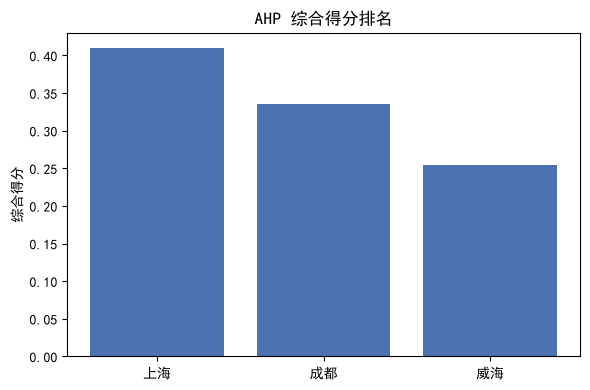

In [ ]:
# 可视化综合得分
order = np.argsort(-score)                  # 从高到低排序
plt.figure(figsize=(6, 4))
plt.bar(np.array(places)[order], score[order], color="#4C72B0")
plt.title("AHP 综合得分排名")
plt.ylabel("综合得分")
plt.tight_layout()
plt.show()